<a href="https://colab.research.google.com/github/kesava-00/EPIDEMICS/blob/main/Kesava_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       EPIDEMIC SPREAD OVER 52 WEEKS
       Cayley-Hamilton Matrix Power Method

Initial State:
Susceptible = 900
Infected    = 80
Recovered   = 20

Weekly Transition Matrix A:
[[0.9 0.  0. ]
 [0.1 0.8 0. ]
 [0.  0.2 1. ]]

1. CHARACTERISTIC EQUATION

Characteristic Polynomial:
1.0*lambda**3 - 2.7*lambda**2 + 2.42*lambda - 0.72

Characteristic Equation:
Eq(1.0*lambda**3 - 2.7*lambda**2 + 2.42*lambda - 0.72, 0)

Coefficients:
c1 = -2.7
c2 = 2.42
c3 = -0.7200000000000001

2. CAYLEY-HAMILTON THEOREM

For a 3 x 3 matrix:
A^3 - c1*A^2 + c2*A - c3*I = 0

Therefore:
A^3 = c1*A^2 - c2*A + c3*I

A^3 = -2.700000A^2 - 2.420000A + -0.720000I

3. CALCULATION OF A^52

A^52 using Cayley-Hamilton:
[[151.65318    0.         0.      ]
 [ 16.854055 134.799125   0.      ]
 [  0.99166   34.69977  169.498895]]

Verification:
Maximum difference from NumPy = 168.49889468280577

4. EPIDEMIC STATE AFTER 52 WEEKS

S(52) = 136487.861795
I(52) = 25952.579393
R(52) = 7058.453495

Total population = 169498.894683

5

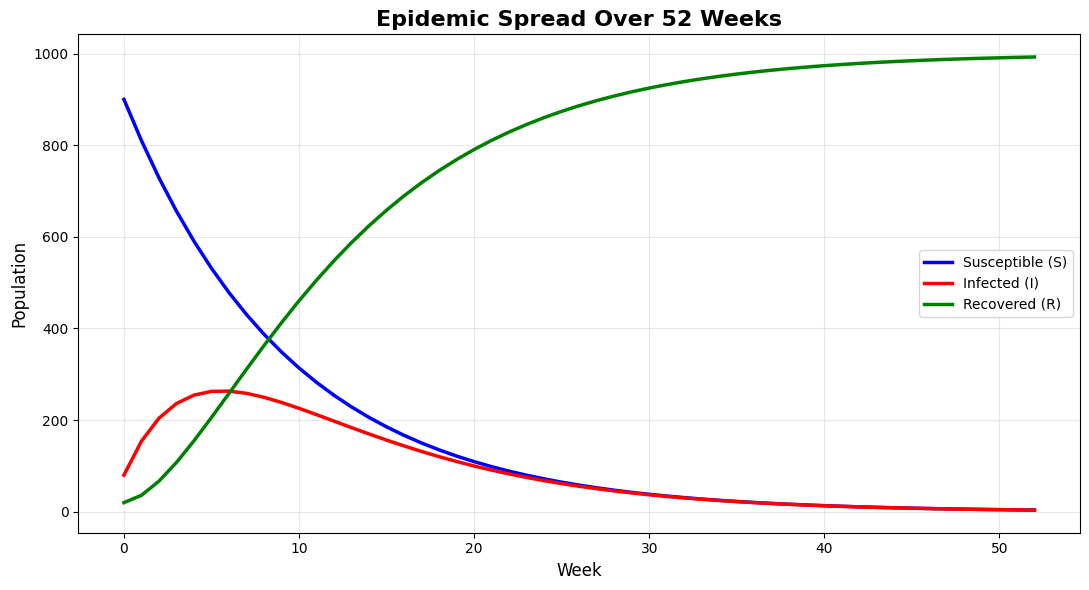


PROJECT SUMMARY

Mathematical Model:
    x(n+1) = A x(n)

After n weeks:
    x(n) = A^n x(0)

Cayley-Hamilton:
    A^3 - c1 A^2 + c2 A - c3 I = 0

Therefore:
    A^3 = c1 A^2 - c2 A + c3 I

One-year epidemic state:
    x(52) = A^52 x(0)

Steady state:
    A x* = x*

The program has:
    1. Calculated the characteristic equation.
    2. Applied the Cayley-Hamilton theorem.
    3. Calculated A^52.
    4. Calculated the epidemic state after 52 weeks.
    5. Displayed all 52 weeks.
    6. Found the steady state.
    7. Plotted S, I and R over time.

                 END OF PROJECT


In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# ============================================================
# EPIDEMIC SPREAD OVER 52 WEEKS (C1)
# Using Cayley-Hamilton Theorem
# ============================================================

# -------------------- INPUT --------------------

# Initial population
S0 = 900
I0 = 80
R0 = 20

# Weekly transition matrix
# x(n+1) = A*x(n)
A = np.array([
    [0.90, 0.00, 0.00],
    [0.10, 0.80, 0.00],
    [0.00, 0.20, 1.00]
], dtype=float)

N = 52

x0 = np.array([S0, I0, R0], dtype=float)

print("=" * 70)
print("       EPIDEMIC SPREAD OVER 52 WEEKS")
print("       Cayley-Hamilton Matrix Power Method")
print("=" * 70)

print("\nInitial State:")
print(f"Susceptible = {S0}")
print(f"Infected    = {I0}")
print(f"Recovered   = {R0}")

print("\nWeekly Transition Matrix A:")
print(A)

# ============================================================
# 1. CHARACTERISTIC POLYNOMIAL
# ============================================================

# Convert A into a SymPy matrix
A_sym = sp.Matrix(A)

lambda_symbol = sp.symbols('lambda')

characteristic_polynomial = A_sym.charpoly(lambda_symbol).as_expr()

print("\n" + "=" * 70)
print("1. CHARACTERISTIC EQUATION")
print("=" * 70)

print("\nCharacteristic Polynomial:")
print(sp.expand(characteristic_polynomial))

print("\nCharacteristic Equation:")
print(sp.Eq(characteristic_polynomial, 0))

# Extract coefficients
# p(lambda) = lambda^3 - c1 lambda^2 + c2 lambda - c3
coefficients = sp.Poly(
    characteristic_polynomial,
    lambda_symbol
).all_coeffs()

c1 = float(coefficients[1])
c2 = float(coefficients[2])
c3 = float(coefficients[3])

print("\nCoefficients:")
print(f"c1 = {c1}")
print(f"c2 = {c2}")
print(f"c3 = {c3}")

# ============================================================
# 2. CAYLEY-HAMILTON THEOREM
# ============================================================

print("\n" + "=" * 70)
print("2. CAYLEY-HAMILTON THEOREM")
print("=" * 70)

print("\nFor a 3 x 3 matrix:")

print("A^3 - c1*A^2 + c2*A - c3*I = 0")

print("\nTherefore:")

print("A^3 = c1*A^2 - c2*A + c3*I")

print(
    f"\nA^3 = {c1:.6f}A^2 "
    f"- {c2:.6f}A "
    f"+ {c3:.6f}I"
)

# ============================================================
# 3. COMPUTE A^52 USING CAYLEY-HAMILTON
# ============================================================

def cayley_hamilton_power(A, n):
    """
    Calculate A^n using the Cayley-Hamilton recurrence.

    For:
        p(lambda) = lambda^3 - c1 lambda^2
                     + c2 lambda - c3

    Cayley-Hamilton gives:
        A^3 = c1 A^2 - c2 A + c3 I

    Hence every higher power can be represented as:
        A^n = alpha*A^2 + beta*A + gamma*I
    """

    A_sym = sp.Matrix(A)
    x = sp.symbols('x')

    polynomial = A_sym.charpoly(x).as_expr()
    coeffs = sp.Poly(polynomial, x).all_coeffs()

    c1 = float(coeffs[1])
    c2 = float(coeffs[2])
    c3 = float(coeffs[3])

    I = np.eye(3)
    A2 = A @ A

    # Special cases
    if n == 0:
        return I

    if n == 1:
        return A

    if n == 2:
        return A2

    # A^2 = 1*A^2 + 0*A + 0*I
    alpha = 1.0
    beta = 0.0
    gamma = 0.0

    for k in range(2, n):

        # Multiply:
        #
        # A^(k+1)
        # = alpha*A^3 + beta*A^2 + gamma*A
        #
        # Use:
        # A^3 = c1*A^2 - c2*A + c3*I

        new_alpha = alpha * c1 + beta
        new_beta = -alpha * c2 + gamma
        new_gamma = alpha * c3

        alpha = new_alpha
        beta = new_beta
        gamma = new_gamma

    return (
        alpha * A2
        + beta * A
        + gamma * I
    )


A52 = cayley_hamilton_power(A, 52)

print("\n" + "=" * 70)
print("3. CALCULATION OF A^52")
print("=" * 70)

print("\nA^52 using Cayley-Hamilton:")

np.set_printoptions(
    precision=6,
    suppress=True
)

print(A52)

# ============================================================
# 4. VERIFY A^52
# ============================================================

A52_numpy = np.linalg.matrix_power(A, 52)

error = np.max(np.abs(A52 - A52_numpy))

print("\nVerification:")
print("Maximum difference from NumPy =", error)

if error < 1e-6:
    print("Cayley-Hamilton calculation verified successfully.")

# ============================================================
# 5. FINAL STATE AFTER 52 WEEKS
# ============================================================

x52 = A52 @ x0

print("\n" + "=" * 70)
print("4. EPIDEMIC STATE AFTER 52 WEEKS")
print("=" * 70)

print(f"\nS(52) = {x52[0]:.6f}")
print(f"I(52) = {x52[1]:.6f}")
print(f"R(52) = {x52[2]:.6f}")

print(f"\nTotal population = {np.sum(x52):.6f}")

# ============================================================
# 6. WEEK-BY-WEEK EVOLUTION
# ============================================================

states = []

current_state = x0.copy()

states.append(current_state.copy())

for week in range(1, N + 1):

    current_state = A @ current_state

    states.append(current_state.copy())

states = np.array(states)

print("\n" + "=" * 70)
print("5. WEEK-BY-WEEK EPIDEMIC EVOLUTION")
print("=" * 70)

print(
    f"{'Week':>6}"
    f"{'Susceptible':>18}"
    f"{'Infected':>18}"
    f"{'Recovered':>18}"
)

print("-" * 70)

for week in range(N + 1):

    print(
        f"{week:>6}"
        f"{states[week, 0]:>18.4f}"
        f"{states[week, 1]:>18.4f}"
        f"{states[week, 2]:>18.4f}"
    )

# ============================================================
# 7. STEADY STATE
# ============================================================

print("\n" + "=" * 70)
print("6. STEADY STATE")
print("=" * 70)

print("\nAt steady state:")
print("A*x* = x*")

print("\nTherefore:")
print("(A - I)x* = 0")

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(A)

print("\nEigenvalues:")

for value in eigenvalues:
    print(value)

# Find eigenvalue closest to 1
index = np.argmin(
    np.abs(eigenvalues - 1)
)

steady_eigenvalue = eigenvalues[index]

steady_vector = np.real(
    eigenvectors[:, index]
)

# Make vector positive
if np.sum(steady_vector) < 0:
    steady_vector = -steady_vector

# Normalize to total population
total_population = np.sum(x0)

steady_state = (
    steady_vector /
    np.sum(steady_vector)
) * total_population

print("\nEigenvalue corresponding to steady state:")
print(steady_eigenvalue)

print("\nSteady State:")

print(f"S* = {steady_state[0]:.6f}")
print(f"I* = {steady_state[1]:.6f}")
print(f"R* = {steady_state[2]:.6f}")

# ============================================================
# 8. VERIFY STEADY STATE
# ============================================================

check = A @ steady_state

print("\nVerification of A*x* = x*:")

print("A*x* =")
print(check)

print("\nx* =")
print(steady_state)

print("\nDifference:")
print(check - steady_state)

# ============================================================
# 9. PLOT EPIDEMIC EVOLUTION
# ============================================================

weeks = np.arange(0, N + 1)

plt.figure(figsize=(11, 6))

plt.plot(
    weeks,
    states[:, 0],
    color="blue",
    linewidth=2.5,
    label="Susceptible (S)"
)

plt.plot(
    weeks,
    states[:, 1],
    color="red",
    linewidth=2.5,
    label="Infected (I)"
)

plt.plot(
    weeks,
    states[:, 2],
    color="green",
    linewidth=2.5,
    label="Recovered (R)"
)

plt.xlabel("Week", fontsize=12)
plt.ylabel("Population", fontsize=12)

plt.title(
    "Epidemic Spread Over 52 Weeks",
    fontsize=16,
    fontweight="bold"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("PROJECT SUMMARY")
print("=" * 70)

print("""
Mathematical Model:
    x(n+1) = A x(n)

After n weeks:
    x(n) = A^n x(0)

Cayley-Hamilton:
    A^3 - c1 A^2 + c2 A - c3 I = 0

Therefore:
    A^3 = c1 A^2 - c2 A + c3 I

One-year epidemic state:
    x(52) = A^52 x(0)

Steady state:
    A x* = x*

The program has:
    1. Calculated the characteristic equation.
    2. Applied the Cayley-Hamilton theorem.
    3. Calculated A^52.
    4. Calculated the epidemic state after 52 weeks.
    5. Displayed all 52 weeks.
    6. Found the steady state.
    7. Plotted S, I and R over time.
""")

print("=" * 70)
print("                 END OF PROJECT")
print("=" * 70)